# Subagent 도구 위임

**이 노트북에서 할 일**

1. 대출 규정 담당(전문 에이전트)을 만들고, 도구 함수 안에서 부르게 감쌉니다.
2. 중앙 에이전트가 그 도구로 일을 맡긴 한 실행에서, 바깥 목록과 안쪽 목록을 나란히 봅니다.
3. 전문 에이전트의 요청까지 모델 요청 수를 세고, 앞 차례 기록을 붙인 실행과 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 중앙 에이전트를 4절과 6절에서 한 번씩 실행합니다.
중앙 에이전트가 한 번 맡기면 실행 한 번에 모델 요청이 3번이라, 모두 6번입니다.
요금표로 어림한 예상 비용은 두 실행을 합쳐 0.003달러 아래이고, 청구 금액이 아닙니다.

모델의 답 글과 맡기는 횟수는 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

읽거나 쓰는 파일은 없습니다.
앞 챕터에서 배운 함수 넷은 도구 파일 `delegation_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 langchain 1.4.0과 langchain-openai 1.6.0입니다.
langgraph 1.2.11과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽습니다.
전문 에이전트를 도구로 감싸고, 한 실행에서 두 메시지 목록을 나란히 보는 자리입니다.
5~6절은 모델 요청 수 세기와 값 바꿔 보기이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch26-delegation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 문의 글 한 줄 반납 날짜를 늘리려면에서 회색 상자 중앙 에이전트 supervisor create_agent 도구 하나로 화살표가 갑니다. 회색 상자에서 도구 요청이라는 화살표가 파란 상자 도구 ask_loan_desk 글 한 줄을 맡기는 함수로 가고, 파란 상자에서 새 목록 한 줄로 invoke라는 화살표가 회색 상자 전문 에이전트 loan_desk 대출 규정 담당 도구 없음으로 갑니다. 초록 상자 교재용 대출·반납 규정 시스템 메시지 글에 넣음도 전문 에이전트로 화살표가 갑니다. 맨 아래 보라 상자 모델 gpt-5.4-mini 두 에이전트가 함께 씀이 두 회색 상자와 화살표 없는 선으로 이어진 그림](attachment:01-1-도구로-감싼-전문-에이전트.png)

위에서 아래로 읽습니다.
초록 상자는 넣은 글, 파란 상자는 우리가 적은 도구 함수, 회색 상자는 create_agent가 만든 에이전트 그래프입니다.
보라 상자는 이 절에서 실제로 부른 모델이고, 화살표 없는 선은 두 에이전트가 모델 객체 하나를 함께 쓴다는 뜻입니다.
전문 에이전트에게 가는 화살표는 도구 함수에서 오는 것 하나뿐이고, 중앙 에이전트와 바로 이어지지 않습니다.
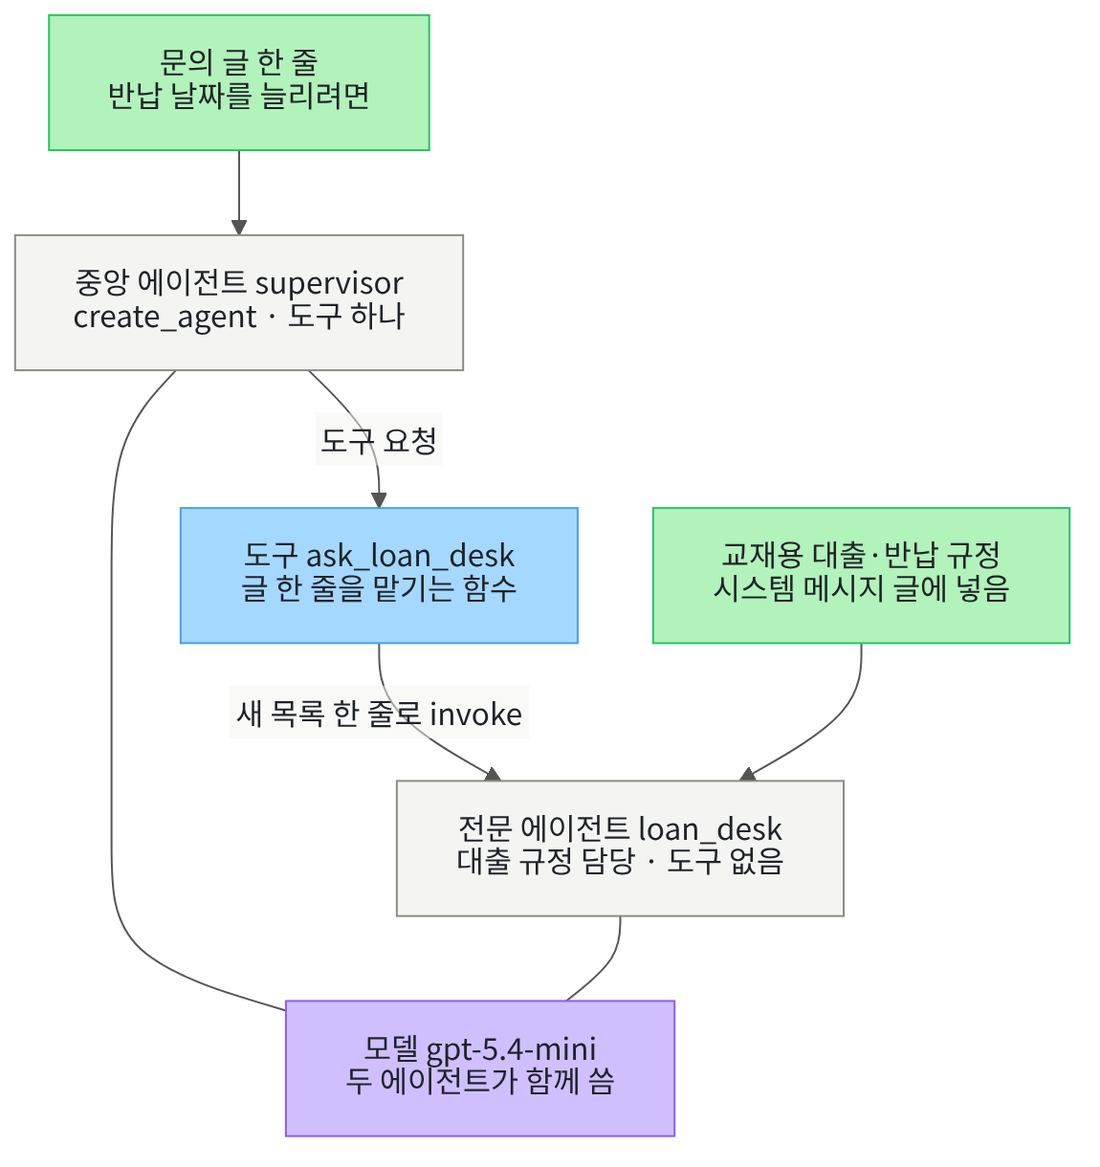

## 1. 준비

이 절에서는 에이전트가 다른 에이전트에게 일을 맡기는 모양을 처음 봅니다.
절 제목의 Subagent는 서브에이전트를 가리키고, 뜻은 3절에서 풉니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langgraph: 1.2.11`이 보입니다.
네 판 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `create_agent`는 Ch 21 01절, 함수 `init_chat_model`은 Ch 6 01절에서 썼습니다.
메시지 클래스 `HumanMessage`와 `AIMessage`는 Ch 13 04절에서 보았습니다.
줄 `@tool`에 쓰는 이름 `tool`은 Ch 19 01절에서 가져왔습니다.
마지막 가져오기 줄은 앞 챕터에서 배운 함수 넷을 도구 파일 `delegation_tools.py`에서 가져옵니다.

In [2]:
# 에이전트(Ch 21 01절)·모델(Ch 6 01절)·메시지(Ch 13 04절)·도구(Ch 19 01절)를 만드는 이름을 가져옵니다
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
# 앞 챕터에서 배운 함수 넷은 도구 파일에서 가져옵니다
from delegation_tools import estimate_cost, show_messages, sum_usage, tool_call_names

print("도구 파일에서 가져온 함수:", "estimate_cost, show_messages, sum_usage, tool_call_names")

도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_call_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, show_messages, sum_usage, tool_call_names`가 보입니다.
Ch 19 06절 함수 `show_messages`는 메시지 목록을 한 줄씩 출력합니다.
Ch 19 04절 함수 `tool_call_names`는 응답 하나에 든 도구 요청의 이름을 모읍니다.
Ch 19 05절 함수 `sum_usage`는 목록 안 응답마다 요청 하나로 세고 토큰을 더합니다.
Ch 6 06절 함수 `estimate_cost`는 사용량과 요금표로 예상 비용을 셉니다.

앞에서 배운 함수는 `delegation_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
이 절의 두 에이전트는 이 모델 객체 하나를 함께 씁니다.

## 2. 대출 규정 담당 만들기

도서관 자료실 문의 창구에, 대출·반납 규정만 맡아 답하는 담당을 둔다고 합시다.
이렇게 한 분야만 맡아 답하는 에이전트를 이 챕터에서는 전문 에이전트라고 부릅니다.
먼저 담당이 근거로 쓸 규정 글을 정합니다.
이 글은 교재용으로 만든 규정이고, 실제 도서관 규정이 아닙니다.

In [5]:
# 대출 규정 담당이 근거로 쓸 규정 글을 정합니다(교재용으로 만든 글 — 실제 도서관 규정이 아님)
loan_rules = "[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다."
loan_rules = loan_rules + " 반납 예정일 전에 한 번, 7일 연장할 수 있습니다."
loan_rules = loan_rules + " 예약한 사람이 있는 책은 연장할 수 없습니다."
loan_rules = loan_rules + " 연체한 일수만큼 새 대출이 제한됩니다."
print("규정 글:")
print(loan_rules)

규정 글:
[교재용 대출·반납 규정] 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다. 반납 예정일 전에 한 번, 7일 연장할 수 있습니다. 예약한 사람이 있는 책은 연장할 수 없습니다. 연체한 일수만큼 새 대출이 제한됩니다.


**결과 읽기** — 라벨 줄 아래에 `[교재용 대출·반납 규정]`으로 시작하는 규정 네 문장이 한 줄로 보입니다.
첫 문장과 마지막 문장은 Ch 21 01절 규정 글의 대출·연체 문장과 같습니다.
연장 두 문장은 이 절에서 더했고, 연장 일수 7은 Ch 24 04절 실습에서 고쳐 넣은 값과 같습니다.

다음 셀은 이 규정 글을 시스템 메시지 글에 넣어 전문 에이전트를 만듭니다.
Ch 21 01절처럼 `create_agent`에 모델 객체, 도구 목록, 시스템 메시지 글을 넘깁니다.
이번에는 도구 목록을 비워 둡니다.
답 길이는 두 문장으로 정해, 답 글이 짧게 끝나게 합니다.

In [6]:
# 규정 글을 시스템 메시지 글에 넣어, 도구가 없는 전문 에이전트(대출 규정 담당)를 만듭니다
loan_desk_text = "도서관 자료실의 대출 규정 담당입니다. 아래 교재용 규정만 근거로 두 문장의 한국어로 답하세요.\n"
loan_desk_text = loan_desk_text + loan_rules
loan_desk = create_agent(model, tools=[], system_prompt=loan_desk_text)
# 도구가 없으면 노드는 모델 하나뿐이라, 한 번 실행에 모델 요청이 한 번입니다
desk_graph = loan_desk.get_graph()
print("대출 규정 담당의 노드:", list(desk_graph.nodes))

대출 규정 담당의 노드: ['__start__', 'model', '__end__']


**결과 읽기** — 출력 줄 `대출 규정 담당의 노드: ['__start__', 'model', '__end__']`가 보입니다.
도구가 없어 도구 실행 노드 `tools`가 없고, 모델 노드를 한 번 지나면 끝납니다.
그래서 이 담당을 한 번 실행하면 모델 요청은 한 번입니다.

## 3. 전문 에이전트를 도구로 감싸기

이제 이 담당을 다른 에이전트가 부를 수 있게 도구로 감쌉니다.
도구 함수 안에서 담당의 `invoke`를 부르면, 담당에게 일을 맡기는 도구가 됩니다.
이렇게 도구로 감싸 불러 쓰는 전문 에이전트를 서브에이전트(subagent)라고 부릅니다.
그 도구를 가지고 문의한 사람과 대화하는 쪽은 중앙 에이전트입니다.

함수 위의 `@tool` 줄은 데코레이터 줄입니다.
데코레이터 줄은 함수 위에 붙여 그 함수를 다른 것으로 감싸는 표시이고, 뜻은 Ch 2 09절에 있습니다.
이 셀에서는 이 줄이 아래 함수를 도구로 등록합니다.
Ch 19 01절처럼 매개변수 `question: str`은 모델이 넘길 인자가 되고, 독스트링은 도구 설명이 됩니다.

도구 함수는 모델이 넘긴 인자만 받습니다.
그래서 담당이 받고 쓴 메시지 목록은 노트북의 기록 목록 `specialist_runs`에 붙여 둡니다.
이 기록 목록은 4절과 6절의 실행 셀에서 새로 만듭니다.

In [7]:
# 문의 글 하나를 대출 규정 담당에게 맡기고, 담당의 마지막 답 글을 내놓는 도구입니다
@tool
def ask_loan_desk(question: str):
    """도서관 대출·반납 규정을 묻는 질문 하나를 대출 규정 담당에게 맡기고, 담당의 답 글을 받습니다."""
    # 담당은 이 글 한 줄만 든 새 메시지 목록으로 일합니다
    inner_input = {"messages": [HumanMessage(content=question)]}
    inner_result = loan_desk.invoke(inner_input)
    # 도구 함수는 모델이 넘긴 인자만 받아, 안쪽 메시지 목록은 노트북의 기록 목록에 붙여 둡니다
    specialist_runs.append(inner_result["messages"])
    return inner_result["messages"][-1].text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담당에게 넘기는 메시지 목록에는 인자 `question`의 글 한 줄만 들어갑니다.
도구가 내놓는 값은 담당의 마지막 답 글이고, 이 글이 중앙 에이전트 쪽 도구 메시지의 내용이 됩니다.

다음 셀은 중앙 에이전트의 모델이 보게 될 도구 이름과 설명과 인자를 봅니다.

In [8]:
# 중앙 에이전트의 모델이 보게 될 도구 이름·설명·인자를 봅니다
print("도구 이름:", ask_loan_desk.name)
print("도구 설명:", ask_loan_desk.description)
print("인자:", ask_loan_desk.args)

도구 이름: ask_loan_desk
도구 설명: 도서관 대출·반납 규정을 묻는 질문 하나를 대출 규정 담당에게 맡기고, 담당의 답 글을 받습니다.
인자: {'question': {'title': 'Question', 'type': 'string'}}


**결과 읽기** — 출력 줄 `도구 이름: ask_loan_desk`와 `인자: {'question': {'title': 'Question', 'type': 'string'}}`가 보입니다.
도구 설명 줄은 함수의 독스트링과 같은 글입니다.
중앙 에이전트의 모델은 이 설명을 읽고, 인자 `question`에 넣을 글을 스스로 씁니다.
담당의 규정 글과 시스템 메시지 글은 이 도구 정보에 들어 있지 않습니다.

다음 셀은 이 도구 하나를 가진 중앙 에이전트를 만듭니다.
시스템 메시지 글에는 대출·반납 규정 질문을 도구에 맡기라고 적고, 답 길이를 두 문장으로 정합니다.
코드 이름 `supervisor`는 공식 문서가 중앙 에이전트를 달리 부르는 이름에서 땄습니다.

In [9]:
# 도구 하나를 가진 중앙 에이전트를 만듭니다(코드 이름 supervisor — 요청은 아직 보내지 않음)
central_text = "도서관 자료실 문의 창구의 안내 도우미입니다."
central_text = central_text + " 대출·반납 규정을 묻는 질문은 직접 답하지 말고 ask_loan_desk 도구에 맡기세요."
central_text = central_text + " 도구가 준 답을 바탕으로 두 문장의 한국어로 답하세요."
supervisor = create_agent(model, tools=[ask_loan_desk], system_prompt=central_text)
supervisor_graph = supervisor.get_graph()
print("중앙 에이전트의 노드:", list(supervisor_graph.nodes))

중앙 에이전트의 노드: ['__start__', 'model', 'tools', '__end__']


**결과 읽기** — 출력 줄 `중앙 에이전트의 노드: ['__start__', 'model', 'tools', '__end__']`가 보입니다.
Ch 21 01절처럼 모델 노드와 도구 실행 노드가 있는 에이전트 그래프입니다.
도구 실행 노드가 도구 `ask_loan_desk`를 부르면, 그 안에서 담당의 그래프가 따로 실행됩니다.

다음 셀은 중앙 에이전트를 실행할 때 줄 실행 한도를 정합니다.
실행 한도는 Ch 20 03절에서 본 그래프 단계 수의 상한입니다.
중앙 에이전트가 도구를 끝없이 부르면 요청도 끝없이 나가므로, 한도를 작게 주어 몇 단계 안에서 멈추게 합니다.

In [10]:
# 모델이 도구를 끝없이 부르더라도 몇 단계 안에서 멈추도록, 실행 한도를 작게 정합니다(Ch 20 03절)
print("create_agent 그래프의 기본 실행 한도:", supervisor.config["recursion_limit"])
run_limit = {"recursion_limit": 10}
print("이 절에서 줄 실행 한도:", run_limit["recursion_limit"])

create_agent 그래프의 기본 실행 한도: 9999
이 절에서 줄 실행 한도: 10


**결과 읽기** — 출력 줄 `create_agent 그래프의 기본 실행 한도: 9999`와 `이 절에서 줄 실행 한도: 10`이 보입니다.
기본값 그대로면 멈추기 전에 요청이 아주 많이 나갈 수 있습니다.
한 번 맡기는 실행은 모델 노드, 도구 실행 노드, 모델 노드의 세 단계라 한도 10 안에서 끝납니다.
한도를 넘는 장면은 이번에 실행하지 않았습니다.

이 한도는 도구 함수 안에서 부른 담당의 실행에는 닿지 않습니다.
함수 `create_agent`가 담당의 그래프에도 기본 한도 9999를 붙여 두기 때문입니다.
노트북 밖 모델 없는 작은 그래프로 확인했고, 노트북에서는 실행하지 않았습니다.

## 4. 한 번 실행하고 두 목록 보기

문의 글은 Ch 25 04절 실습의 대출 연장 문의를 그대로 씁니다.
실행 전에 예상해 봅니다.
중앙 에이전트가 담당에게 한 번 맡기면, 모델 요청은 중앙 둘과 담당 하나로 모두 3번일 것입니다.

다음 셀은 기록 목록을 새로 만들고, 문의 한 줄로 중앙 에이전트를 실행합니다.
설정 자리에는 3절에서 정한 실행 한도를 넘깁니다.

In [11]:
# 기록 목록을 새로 만들고, 대출 연장 문의 한 줄로 중앙 에이전트를 실행합니다(한 번 맡기면 모델 요청 3번)
specialist_runs = []
question_text = "빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?"
first_input = {"messages": [HumanMessage(content=question_text)]}
first_result = supervisor.invoke(first_input, run_limit)
outer_messages = first_result["messages"]
print("바깥 목록의 메시지 수:", len(outer_messages))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))

바깥 목록의 메시지 수: 4
전문 에이전트를 부른 횟수: 1


**결과 읽기** — 출력 줄 `바깥 목록의 메시지 수: 4`와 `전문 에이전트를 부른 횟수: 1`이 보입니다.
중앙 에이전트가 이번 실행에서 담당에게 한 번 맡겼습니다.
이 절은 중앙 에이전트의 메시지 목록을 바깥 목록, 담당이 받고 쓴 목록을 안쪽 목록이라고 부릅니다.

맡기는 횟수는 모델이 정하는 값이라 실행마다 달라질 수 있습니다.
노트북 밖에서 같은 문의를 다섯 번 보냈을 때는 다섯 번 모두 한 번 맡겼습니다.

다음 셀은 바깥 목록을 Ch 19 06절 함수 `show_messages`로 한 줄씩 출력합니다.

In [12]:
# 중앙 에이전트의 메시지 목록(바깥 목록)을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("바깥 목록:")
show_messages(outer_messages)

바깥 목록:
HumanMessage
AIMessage | 도구 호출 요청: ['ask_loan_desk']
ToolMessage | 결과 상태: success | 내용: 반납 예정일 전에 한 번만 7일 연장할 수 있습니다. 다만 예약한 사람이 있는 책은 연장할 수 없습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래에 넷째 줄까지 보입니다.
둘째 줄 `AIMessage | 도구 호출 요청: ['ask_loan_desk']`는 중앙 에이전트의 첫 응답입니다.
셋째 줄 `ToolMessage`는 도구가 내놓은 담당의 답 글이고, 넷째 줄은 도구 요청이 없는 마지막 응답입니다.

셋째 줄의 내용은 담당이 쓴 답 글이라 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.

다음 셀은 중앙 에이전트의 첫 응답에서, 담당에게 넘긴 글을 꺼냅니다.
넘긴 글은 중앙 에이전트의 모델이 인자 `question`에 쓴 글입니다.

In [13]:
# 중앙 에이전트의 첫 응답에서 도구 이름과, 담당에게 넘긴 글을 꺼냅니다
first_response = outer_messages[1]
print("도구 이름:", tool_call_names(first_response))
passed_text = first_response.tool_calls[0]["args"]["question"]
print("넘긴 글:", passed_text)

도구 이름: ['ask_loan_desk']
넘긴 글: 빌린 책의 반납 날짜를 늘리려면 어떻게 하나요?


**결과 읽기** — 출력 줄 `도구 이름: ['ask_loan_desk']`가 보입니다.
둘째 줄은 중앙 에이전트가 인자로 쓴 글이고, 이 글이 담당이 받는 유일한 글입니다.

이번 실행에서는 넘긴 글이 4절 첫 셀의 문의 글을 고치지 않은 그대로였습니다.
모델이 쓰는 인자라, 다른 실행에서는 고쳐 쓴 글을 넘길 수도 있습니다.

다음 셀은 기록 목록에 붙여 둔 안쪽 목록을 꺼내 봅니다.
도구가 한 번 불렸으니 기록 목록의 첫 항목이 그 목록입니다.

In [14]:
# 기록 목록에 붙여 둔, 담당이 받고 쓴 메시지 목록(안쪽 목록)을 봅니다
inner_messages = specialist_runs[0]
print("안쪽 목록의 메시지 수:", len(inner_messages))
print("안쪽 목록:")
show_messages(inner_messages)

안쪽 목록의 메시지 수: 2
안쪽 목록:
HumanMessage
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `안쪽 목록의 메시지 수: 2`가 보입니다.
라벨 줄 아래에는 `HumanMessage`와 `AIMessage | 도구 호출 요청: []` 두 줄이 있습니다.
담당은 넘긴 글 한 줄만 받고, 답을 한 번 써서 끝났습니다.
바깥 목록의 도구 요청 응답과 도구 메시지는 안쪽 목록에 없습니다.

두 목록을 나란히 견주려고, 메시지 종류 이름만 모으는 함수를 만듭니다.
Ch 21 01절에서 메시지 칸의 종류 이름을 모은 반복문을 함수로 묶었습니다.

In [15]:
# 메시지 목록에서 종류 이름만 차례대로 모아 목록으로 내놓습니다
def message_kinds(messages):
    kinds = []
    for message in messages:
        kinds.append(type(message).__name__)
    return kinds

**결과 읽기** — 정의 셀이라 출력이 없습니다.
같은 이름을 담은 목록이 나오므로, 목록 메서드 `count`로 한 종류의 수를 셀 수 있습니다.

다음 셀은 두 목록의 종류를 나란히 보고, 시스템 메시지가 있는지 셉니다.

In [16]:
# 바깥 목록과 안쪽 목록의 종류를 나란히 보고, 시스템 메시지가 있는지 셉니다
outer_kinds = message_kinds(outer_messages)
inner_kinds = message_kinds(inner_messages)
print("바깥 목록:", outer_kinds)
print("안쪽 목록:", inner_kinds)
print("시스템 메시지 수(바깥, 안쪽):", outer_kinds.count("SystemMessage"), inner_kinds.count("SystemMessage"))

바깥 목록: ['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']
안쪽 목록: ['HumanMessage', 'AIMessage']
시스템 메시지 수(바깥, 안쪽): 0 0


**결과 읽기** — 출력 줄 `바깥 목록: ['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
출력 줄 `안쪽 목록: ['HumanMessage', 'AIMessage']`와 `시스템 메시지 수(바깥, 안쪽): 0 0`도 보입니다.
Ch 21 01절에서 본 것처럼, 에이전트는 시스템 메시지 글을 메시지 칸에 담지 않습니다.
그래서 담당의 규정 글은 담당의 요청에만 실리고, 두 목록 어디에도 없습니다.

Ch 8 03절의 나누기(Isolate)는 업무마다 메시지 목록을 따로 만들어 보내는 일이었습니다.
담당은 중앙 에이전트의 목록이 아니라, 넘긴 글 한 줄로 시작한 자기 목록으로 일했습니다.

다음 셀은 두 목록이 이어지는 자리를 확인합니다.
안쪽 첫 글은 넘긴 글과 같아야 하고, 바깥의 도구 메시지 내용은 안쪽 마지막 답 글과 같아야 합니다.

In [17]:
# 두 목록이 이어지는 자리를 봅니다(안쪽 첫 글과 넘긴 글, 도구 메시지와 안쪽 마지막 답 글)
print("안쪽 첫 글이 넘긴 글과 같은가:", inner_messages[0].content == passed_text)
tool_message = outer_messages[2]
inner_answer = inner_messages[-1].text
print("도구 메시지 내용이 안쪽 마지막 답 글과 같은가:", tool_message.content == inner_answer)

안쪽 첫 글이 넘긴 글과 같은가: True
도구 메시지 내용이 안쪽 마지막 답 글과 같은가: True


**결과 읽기** — 두 줄 모두 `True`입니다.
두 목록은 넘긴 글 하나와 답 글 하나로만 이어져 있습니다.
담당이 쓴 응답 객체는 바깥 목록에 들어가지 않고, 그 글만 도구 메시지로 옮겨졌습니다.

다음 셀은 중앙 에이전트가 문의한 사람에게 줄 마지막 답 글을 봅니다.

In [18]:
# 중앙 에이전트가 문의한 사람에게 줄 마지막 답 글을 봅니다(실행마다 달라질 수 있는 값)
final_answer = outer_messages[-1].text
print("최종 답 글:")
print(final_answer)
print("글자 수:", len(final_answer))

최종 답 글:
반납 예정일 전에 한 번만 7일 연장할 수 있습니다.  
다만 예약한 사람이 있는 책은 연장할 수 없습니다.
글자 수: 60


**결과 읽기** — 라벨 줄 `최종 답 글:` 아래는 중앙 에이전트가 담당의 답을 바탕으로 쓴 안내 글입니다.
답 글은 실행마다 달라질 수 있어, 이 절의 결론에 쓰지 않습니다.

이번 실행에서는 답 글이 두 줄이었고, 출력 줄 `글자 수: 60`입니다.
담당의 답 글과 같은 두 문장을 두 줄로 나눠 쓴 글이었습니다.

## 5. 모델 요청 수 세기

Ch 19 05절 함수 `sum_usage`는 한 목록 안의 응답마다 요청 하나로 셉니다.
그런데 담당의 응답은 안쪽 목록에만 있고, 바깥 목록에는 없습니다.
실행 전에 예상해 봅니다.
바깥 목록만 세면 담당의 요청이 빠져, 요청 수가 2로 나올 것입니다.

In [19]:
# 바깥 목록만 Ch 19 05절 함수 sum_usage로 세고, 바깥 목록의 응답 수와 견줍니다
outer_usage = sum_usage(outer_messages)
print("바깥 목록만 센 요청 수:", outer_usage["requests"])
print("바깥 목록의 응답 수:", outer_kinds.count("AIMessage"))

바깥 목록만 센 요청 수: 2
바깥 목록의 응답 수: 2


**결과 읽기** — 출력 줄 `바깥 목록만 센 요청 수: 2`와 `바깥 목록의 응답 수: 2`가 보입니다.
바깥 목록만 세면 중앙 에이전트의 요청 둘만 셉니다.

다음 셀은 기록 목록의 안쪽 목록마다 요청 수를 셉니다.

In [20]:
# 기록 목록의 안쪽 목록마다 요청 수를 셉니다(바깥 목록에 없던 담당의 요청)
for inner_list in specialist_runs:
    inner_usage = sum_usage(inner_list)
    print("안쪽 목록 요청 수:", inner_usage["requests"])

안쪽 목록 요청 수: 1


**결과 읽기** — 출력 줄 `안쪽 목록 요청 수: 1`이 한 줄 보입니다.
바깥 목록에서 빠졌던 담당의 요청 하나가 여기에 있습니다.

두 값을 한꺼번에 더하는 함수를 만듭니다.
바깥 목록에는 우리가 넣은 메시지도 들어 있어, 함수는 이번 실행이 더한 바깥 메시지만 받습니다.
넣은 메시지를 빼야 하는 까닭은 6절에서 출력으로 봅니다.

In [21]:
# 이번 실행이 더한 바깥 메시지와 안쪽 목록 여럿의 요청 수·토큰을 모두 더해 내놓습니다
def usage_with_specialists(new_messages, inner_runs):
    total = sum_usage(new_messages)
    for inner_list in inner_runs:
        inner_usage = sum_usage(inner_list)
        # 요청 수·입력 토큰·출력 토큰 세 키를 차례로 더합니다
        for key in total:
            total[key] = total[key] + inner_usage[key]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
안쪽 반복문은 딕셔너리의 키 셋(요청 수·입력 토큰·출력 토큰)을 차례로 더합니다.

다음 셀은 넣은 메시지 뒤, 이번 실행이 더한 바깥 메시지만 잘라 담당의 요청과 함께 셉니다.
자르기 `목록[n:]`은 Ch 16 01절처럼 앞 n개를 뺀 나머지를 내놓습니다.

In [22]:
# 넣은 메시지 뒤, 이번 실행이 더한 바깥 메시지만 잘라 담당의 요청과 함께 셉니다
input_count = len(first_input["messages"])
first_new = outer_messages[input_count:]
first_total = usage_with_specialists(first_new, specialist_runs)
print("이번 실행이 더한 바깥 메시지 수:", len(first_new))
print("모델 요청 수(중앙 + 전문):", first_total["requests"])
print("입력 토큰:", first_total["input_tokens"], "| 출력 토큰:", first_total["output_tokens"])

이번 실행이 더한 바깥 메시지 수: 3
모델 요청 수(중앙 + 전문): 3
입력 토큰: 685 | 출력 토큰: 104


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지 수: 3`과 `모델 요청 수(중앙 + 전문): 3`이 보입니다.
앞 두 셀의 요청 2와 요청 1을 더한 값입니다.
한 번 맡기면 요청은 중앙 둘과 담당 하나입니다.
중앙 둘은 도구를 요청한 응답과 마지막 응답이고, 담당 하나는 도구가 없는 담당의 응답입니다.

이번 실행에서는 출력 줄 `입력 토큰: 685 | 출력 토큰: 104`입니다.
토큰 수는 답 글 길이에 따라 실행마다 달라질 수 있습니다.

다음 셀은 Ch 6 06절 함수 `estimate_cost`로 이번 실행의 예상 비용을 셉니다.
요금은 과정 요금표(2026-09-17)의 100만 토큰당 달러이고, 예상 비용은 청구 금액이 아닙니다.

In [23]:
# 2026-09-17 요금표(100만 토큰당 달러)로 이번 실행의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
first_cost = estimate_cost(first_total, input_rate, cached_input_rate, output_rate)
rounded_cost = round(first_cost, 6)
print("예상 비용(달러):", rounded_cost)

예상 비용(달러): 0.000982


**결과 읽기** — 출력 줄 `예상 비용(달러):`에 이번 실행의 어림값이 보입니다.
토큰 수가 실행마다 달라, 이 값도 달라질 수 있습니다.
합친 사용량에는 캐시 입력 칸이 없어, 입력 토큰을 모두 입력 요금으로 셉니다.

이번 실행에서는 `예상 비용(달러): 0.000982`였습니다.
바깥 목록만 세었다면 담당의 토큰이 빠진 만큼 작게 어림했을 것입니다.

## 6. 값 바꿔 보기: 앞 차례 기록을 붙이면

값 하나만 바꿔 봅니다.
바꿀 값은 중앙 에이전트에게 넣는 메시지 목록입니다.
같은 문의 앞에, 앞 차례에 주고받은 대화 두 줄을 손으로 적어 붙입니다.
실행 전에 예상해 봅니다.
바깥 목록은 두 줄 늘고, 안쪽 목록은 두 줄 그대로일 것입니다.

In [24]:
# 앞 차례에 주고받은 대화 두 줄을 손으로 적고, 같은 대출 연장 문의를 뒤에 붙입니다
history = [
    HumanMessage(content="자료실은 토요일에도 여나요?"),
    AIMessage(content="네, 토요일에는 10:00~17:00에 운영합니다."),
]
second_messages = history + [HumanMessage(content=question_text)]
print("중앙 에이전트에게 넣을 메시지 수:", len(second_messages))
print("손으로 적은 응답의 사용량:", history[1].usage_metadata)

중앙 에이전트에게 넣을 메시지 수: 3
손으로 적은 응답의 사용량: None


**결과 읽기** — 출력 줄 `중앙 에이전트에게 넣을 메시지 수: 3`이 보입니다.
출력 줄 `손으로 적은 응답의 사용량: None`처럼, 손으로 적은 응답에는 사용량이 없습니다.
함수 `sum_usage`는 목록 안의 `AIMessage`를 모두 요청으로 세므로, 이 응답도 요청으로 셉니다.
사용량이 `None`이라 이 목록째 넘기면 토큰 수를 꺼내다 멈춥니다.
노트북에서는 이 장면을 실행하지 않았고, 노트북 밖에서 확인했습니다.

다음 셀은 기록 목록을 새로 만들고, 세 줄을 넣어 중앙 에이전트를 한 번 더 실행합니다.

In [25]:
# 기록 목록을 새로 만들고, 세 줄을 넣어 중앙 에이전트를 한 번 더 실행합니다(한 번 맡기면 모델 요청 3번)
specialist_runs = []
second_input = {"messages": second_messages}
second_result = supervisor.invoke(second_input, run_limit)
second_outer = second_result["messages"]
print("바깥 목록:", message_kinds(second_outer))
print("전문 에이전트를 부른 횟수:", len(specialist_runs))

바깥 목록: ['HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']
전문 에이전트를 부른 횟수: 1


**결과 읽기** — 출력 줄 `바깥 목록: ['HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
앞 두 줄은 우리가 넣은 기록이고, 뒤 넷은 4절 실행과 같은 모양입니다.
출력 줄 `전문 에이전트를 부른 횟수: 1`로, 이번에도 한 번 맡겼습니다.

다음 셀은 두 번째 실행의 안쪽 목록을 보고, 앞 차례 글이 들어 있는지 봅니다.

In [26]:
# 두 번째 실행의 안쪽 목록을 보고, 앞 차례 글(토요일)이 안쪽 목록에 들어 있는지 봅니다
second_inner = specialist_runs[0]
print("안쪽 목록:", message_kinds(second_inner))
history_found = False
for message in second_inner:
    if "토요일" in message.text:
        history_found = True
print("안쪽 목록에 앞 차례 글이 있는가:", history_found)

안쪽 목록: ['HumanMessage', 'AIMessage']
안쪽 목록에 앞 차례 글이 있는가: False


**결과 읽기** — 출력 줄 `안쪽 목록: ['HumanMessage', 'AIMessage']`와 `안쪽 목록에 앞 차례 글이 있는가: False`가 보입니다.
바깥 목록이 늘어도, 담당은 넘긴 글 한 줄로 시작한 두 줄 목록으로 일했습니다.

다음 셀은 넣은 세 줄 뒤, 이번 실행이 더한 바깥 메시지만 잘라 요청 수를 셉니다.

In [27]:
# 넣은 세 줄 뒤, 이번 실행이 더한 바깥 메시지만 잘라 요청 수를 셉니다
second_count = len(second_messages)
second_new = second_outer[second_count:]
second_total = usage_with_specialists(second_new, specialist_runs)
print("이번 실행이 더한 바깥 메시지:", message_kinds(second_new))
print("모델 요청 수(중앙 + 전문):", second_total["requests"])
print("입력 토큰:", second_total["input_tokens"], "| 출력 토큰:", second_total["output_tokens"])

이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']
모델 요청 수(중앙 + 전문): 3
입력 토큰: 757 | 출력 토큰: 101


**결과 읽기** — 출력 줄 `이번 실행이 더한 바깥 메시지: ['AIMessage', 'ToolMessage', 'AIMessage']`가 보입니다.
출력 줄 `모델 요청 수(중앙 + 전문): 3`으로, 4절과 같은 셈이 나왔습니다.
넣은 세 줄을 잘라 내자 손으로 적은 응답이 빠지고, 중앙 둘과 담당 하나가 남았습니다.

이번 실행에서는 출력 줄 `입력 토큰: 757 | 출력 토큰: 101`입니다.
앞 차례 기록 두 줄이 중앙 에이전트의 요청에 함께 실려, 이번 실행에서는 입력 토큰이 4절보다 많았습니다.

다음 셀은 두 실행의 바깥 줄 수·안쪽 줄 수·모델 요청 수를 한 줄씩 견줍니다.

In [28]:
# 두 실행의 바깥 줄 수·안쪽 줄 수·모델 요청 수를 한 줄씩 견줍니다
print("실행 | 바깥 줄 수 | 안쪽 줄 수 | 모델 요청 수")
print("문의 한 줄 |", len(outer_messages), "|", len(inner_messages), "|", first_total["requests"])
print("앞 차례 기록 + 문의 |", len(second_outer), "|", len(second_inner), "|", second_total["requests"])

실행 | 바깥 줄 수 | 안쪽 줄 수 | 모델 요청 수
문의 한 줄 | 4 | 2 | 3
앞 차례 기록 + 문의 | 6 | 2 | 3


**결과 읽기** — 라벨 줄 아래 `문의 한 줄 | 4 | 2 | 3`과 `앞 차례 기록 + 문의 | 6 | 2 | 3`이 보입니다.
바깥 줄 수만 두 줄 늘고, 안쪽 줄 수와 모델 요청 수는 같았습니다.
앞 차례 기록은 중앙 에이전트의 목록에만 쌓이고, 담당에게는 넘어가지 않았습니다.

## 정리

1. 전문 에이전트를 도구 함수 안에서 부르게 감싸면, 중앙 에이전트는 도구를 고르듯 일을 맡깁니다.
2. 담당은 넘긴 글 한 줄로 시작한 두 줄짜리 안쪽 목록으로 일했고, 바깥 목록에는 답 글만 도구 메시지로 들어왔습니다.
3. 바깥 목록만 세면 담당의 요청이 빠지고, 한 번 맡기면 모델 요청은 중앙 2 + 전문 1입니다.

02절에서는 담당에게 일을 맡겼다 답을 받는 대신, 다음 차례에 대화할 담당 자체를 바꾸는 모양을 봅니다.